# Taxas suavizadas dos municípios pequenos

O teste de estabilidade mais exigente do notebook 05 foi a retirada dos 149
municípios com menos de 5.000 habitantes (ARI de 0,480 no modelo escolhido).
Nesses municípios, uma única ocorrência a mais ou a menos muda bastante a
taxa por 100 mil habitantes. Este notebook substitui as 9 taxas criminais
por taxas **suavizadas** pelo estimador bayesiano empírico global e verifica
se os perfis se mantêm e se a partição fica mais estável.

Saídas:

- `data/processed/tabela_taxas_suavizadas.csv`: as medidas de comparação,
  com o valor original e o valor com taxas suavizadas lado a lado;
- `data/processed/perfis_suavizados.csv`: o perfil original e o perfil com
  taxas suavizadas de cada município;
- figura de apoio: `figura_taxas_suavizadas`.

### Critérios definidos antes da execução

- **Leitura do ARI**: as mesmas faixas do notebook 08 (`FAIXAS_ARI`,
  confirmadas pelo grupo em 28/10/2026).

  | ARI | Leitura |
  |---|---|
  | ≥ 0,80 | os perfis se mantêm |
  | 0,65 a 0,80 | os perfis mudam em parte; descrever quais |
  | < 0,65 | os perfis dependem da mudança testada |

- **Conferência da suavização**: nos municípios com mais de 100 mil
  habitantes, a taxa suavizada deveria diferir menos de 5% da bruta
  (`POPULACAO_GRANDE` e `DIFERENCA_MAXIMA_GRANDES`, no `config.py`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Os notebooks ficam em notebooks/ e o código do projeto em src/. Estas duas
# linhas apontam o Python para src/, para os "from config import ..." abaixo
# funcionarem tanto rodando daqui quanto da raiz do projeto.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

from config import (ALGORITMO_ESCOLHIDO, ANOS_JANELA, BASE_FINAL_CSV,
                    DATA_PROCESSED, DICIONARIO_CSV, DIFERENCA_MAXIMA_GRANDES,
                    K_ESCOLHIDO, POPULACAO_GRANDE, SSP_COBERTURA_CSV,
                    SSP_PAINEL_CSV)
from estilo import aplicar_estilo, salvar
from figuras import plot_taxas_suavizadas
from preprocessamento import (carregar_features, montar_matriz,
                              suavizar_taxas, taxas_da_janela)
from clusterizacao import ari_sem_pequenos, faixa_ari, refazer_particao

aplicar_estilo()   # mesma fonte, cores e grade em todas as figuras do artigo
# Se algum import acima falhar, quase sempre é o editor apontando para outra
# instalação do Python. O caminho impresso aqui é o que precisa ter as
# bibliotecas do requirements.txt.
print("Python:", sys.executable)
print(f"Modelo escolhido: {ALGORITMO_ESCOLHIDO}, k = {K_ESCOLHIDO}")

# O código do IBGE é identificador, não quantidade: lido como texto para não
# virar número em nenhuma etapa.
base = pd.read_csv(BASE_FINAL_CSV, dtype={"codigo_ibge": str})
dic = pd.read_csv(DICIONARIO_CSV)
painel = pd.read_csv(SSP_PAINEL_CSV, dtype={"codigo_ibge": str})
cobertura = pd.read_csv(SSP_COBERTURA_CSV)
perfis = pd.read_csv(DATA_PROCESSED / "perfis.csv", dtype={"codigo_ibge": str})
# Saída do notebook 05, para conferir os valores originais recalculados aqui.
comparacao = pd.read_csv(DATA_PROCESSED / "tabela_comparacao_algoritmos.csv")

Python: D:\RP 2\database-rp2\.venv\Scripts\python.exe
Modelo escolhido: kmeans, k = 4


## 1. O estimador bayesiano empírico global

A taxa bruta de um município pequeno é pouco confiável: com 2.000
habitantes, uma ocorrência a mais em três anos acrescenta cerca de 17 por
100 mil habitantes por ano. O estimador bayesiano empírico global (Marshall,
1991), empregado por Assunção et al. (1998) para taxas de municípios
brasileiros, substitui cada taxa por uma média entre a taxa do próprio
município e a taxa do conjunto, com peso `C` para a primeira e `1 − C` para
a segunda. Para cada natureza criminal, com `y` as ocorrências do município
na janela e `n` as pessoas-ano (população × exposição de 3 anos):

```
r   = y / n                                   taxa bruta
m   = soma(y) / soma(n)                       taxa do conjunto
s²  = soma(n · (r − m)²) / soma(n) − m / média(n),  e 0 se der negativo
C   = s² / (s² + m / n)
r_suavizada = m + C · (r − m)
```

`s²` estima o quanto as taxas variam de fato entre os municípios, já
descontada a variação que se espera só pelo acaso. `C` fica perto de 1 nos
municípios grandes, cuja taxa quase não muda, e perto de 0 nos pequenos,
cuja taxa é puxada para `m`. As fórmulas foram conferidas na documentação da
função `EBest` do pacote `spdep` do R, que remete a Marshall (1991) e a
Bailey e Gatrell (1995, p. 303–306), e no código da classe `Empirical_Bayes`
do pacote `esda` (PySAL). As duas coincidem com a implementação de
`suavizar_taxas`, em `src/preprocessamento.py`.

A taxa do conjunto `m` é calculada sobre os 644 municípios da modelagem, isto
é, o estado sem a capital, pelo mesmo motivo de a padronização ser ajustada
apenas neles: a capital não participa do agrupamento.

In [2]:
features, bloco_de = carregar_features(dic)
taxas_crime = [c for c in features if bloco_de[c] == "criminalidade"]
# Mesmo filtro e mesma ordem do notebook 05 (sem a capital, que não tem IEGM).
modelagem = base[~base["flag_sem_iegm"]].reset_index(drop=True)
assert (modelagem["codigo_ibge"] == perfis["codigo_ibge"]).all(), \
    "perfis.csv fora da ordem da base"
pequeno = modelagem["flag_pop_pequena"].to_numpy()

suavizada = suavizar_taxas(modelagem, painel, cobertura, ANOS_JANELA)
# As taxas brutas refeitas do painel têm que ser as da base; senão a
# comparação bruta x suavizada não estaria comparando a mesma coisa.
bruta = taxas_da_janela(modelagem, painel, cobertura, ANOS_JANELA)
assert np.allclose(bruta[taxas_crime], modelagem[taxas_crime])

for c in taxas_crime:
    C = suavizada[c.replace("taxa_", "c_")]
    assert C.between(0, 1).all(), f"{c}: C fora de 0 a 1"
    # C só depende do tamanho do município: ordenando pela população, ele
    # não pode diminuir. diff() é a diferença de cada valor para o anterior.
    assert (C[modelagem["populacao"].sort_values().index].diff().dropna()
            >= -1e-12).all(), f"{c}: C não cresce com a população"
    # A taxa suavizada fica sempre entre a bruta e a do conjunto: nunca se
    # afasta da bruta mais do que a bruta está longe da média.
    ocorrencias = modelagem[c] * modelagem["populacao"]
    m = ocorrencias.sum() / modelagem["populacao"].sum()
    assert ((suavizada[c] - modelagem[c]).abs()
            <= (m - modelagem[c]).abs() + 1e-9).all(), f"{c}: passou da média"
print(f"ok: {len(taxas_crime)} taxas suavizadas em {len(modelagem)} municípios")

ok: 9 taxas suavizadas em 644 municípios


## 2. Quanto de cada taxa é mantido

A tabela mostra, por natureza criminal, a taxa do conjunto (`m`, por 100 mil
hab./ano) e a mediana de `C`, separadamente nos 149 municípios com menos de
5.000 habitantes e nos 495 demais. Quanto menor o `C`, mais a taxa do
município foi puxada para a taxa do conjunto.

In [3]:
pop = modelagem["populacao"]
confianca = pd.DataFrame({
    # Taxa do conjunto (m), por 100 mil hab./ano: todas as ocorrências dos
    # 644 divididas por toda a população.
    "taxa_do_conjunto": [(modelagem[c] * pop).sum() / pop.sum() for c in taxas_crime],
    "mediana_C_pequenos": [suavizada.loc[pequeno, c.replace("taxa_", "c_")].median()
                           for c in taxas_crime],
    "mediana_C_demais": [suavizada.loc[~pequeno, c.replace("taxa_", "c_")].median()
                         for c in taxas_crime],
}, index=taxas_crime)
print(f"{pequeno.sum()} pequenos | {(~pequeno).sum()} demais")
confianca.sort_values("mediana_C_pequenos").round(3)

149 pequenos | 495 demais


,taxa_do_conjunto,mediana_C_pequenos,mediana_C_demais
taxa_cvli,6.495,0.151,0.524
taxa_tentativa_homicidio,8.708,0.191,0.594
taxa_estupro_total,33.794,0.336,0.757
taxa_lesao_dolosa,346.257,0.664,0.924
taxa_trafico,99.940,0.799,0.961
taxa_roubo_veiculo,55.489,0.835,0.969
taxa_furto_veiculo,150.671,0.886,0.980
taxa_furto_outros,918.065,0.924,0.987
taxa_roubo_outros,223.692,0.953,0.992


## 3. Conferência nos municípios grandes

O critério definido antes da execução previa que, nos municípios com mais de
100 mil habitantes, a taxa suavizada diferisse menos de 5% da bruta. A
tabela abaixo mostra, para cada natureza, a mediana de `C` nesses municípios
e a diferença relativa entre a taxa suavizada e a bruta (mediana e máximo),
além de quantos municípios passam dos 5%.

In [4]:
grande = modelagem["populacao"] > POPULACAO_GRANDE
# Diferença relativa: quanto a suavizada se afastou, em proporção da bruta.
diferenca = ((suavizada.loc[grande, taxas_crime] - modelagem.loc[grande, taxas_crime]).abs()
             / modelagem.loc[grande, taxas_crime])
conferencia = pd.DataFrame({
    "mediana_C": [suavizada.loc[grande, c.replace("taxa_", "c_")].median()
                  for c in taxas_crime],
    "diferenca_mediana": diferenca.median(),
    "diferenca_maxima": diferenca.max(),
    "acima_de_5pct": (diferenca > DIFERENCA_MAXIMA_GRANDES).sum(),
}, index=taxas_crime)
conferencia["passa"] = conferencia["acima_de_5pct"] == 0
print(f"{grande.sum()} municípios com mais de {POPULACAO_GRANDE:,} habitantes".replace(",", "."))
print("não passam no critério de 5%:", list(conferencia.index[~conferencia["passa"]]))
conferencia.round(4)

79 municípios com mais de 100.000 habitantes
não passam no critério de 5%: ['taxa_cvli', 'taxa_estupro_total', 'taxa_roubo_veiculo', 'taxa_tentativa_homicidio', 'taxa_trafico']


,mediana_C,diferenca_mediana,diferenca_maxima,acima_de_5pct,passa
taxa_cvli,0.9174,0.0227,0.4089,18,False
taxa_estupro_total,0.9692,0.0061,0.0552,1,False
taxa_furto_outros,0.9987,0.0002,0.0017,0,True
taxa_furto_veiculo,0.9979,0.0006,0.0093,0,True
taxa_lesao_dolosa,0.9919,0.0010,0.0089,0,True
taxa_roubo_outros,0.9992,0.0006,0.0116,0,True
taxa_roubo_veiculo,0.9968,0.0021,0.1301,6,False
taxa_tentativa_homicidio,0.9365,0.0119,0.1303,10,False
taxa_trafico,0.9960,0.0013,0.0819,1,False


O critério dos 5% **não é cumprido** em cinco das nove naturezas: CVLI (18
dos 79 municípios grandes acima de 5%), tentativa de homicídio (10), roubo
de veículo (6), estupro (1) e tráfico (1). A falha foi investigada antes de
seguir. Nos municípios grandes, a mediana de `C` fica entre 0,917 (CVLI) e
0,999 (roubo de outros), e a diferença mediana entre a taxa suavizada e a
bruta não passa de 2,27% (CVLI) em nenhuma natureza. A diferença acima de
5% aparece nos crimes mais raros, em que `C` fica abaixo de 1 mesmo com mais
de 100 mil habitantes, e nos municípios cuja taxa bruta está bem abaixo da
taxa do conjunto, em que um deslocamento pequeno em valor absoluto é grande
em proporção. A célula abaixo mostra os cinco casos de maior diferença no
CVLI.

In [5]:
# Os cinco municípios grandes com a maior diferença no CVLI, para ver de
# onde vem a falha do critério.
pior = diferenca["taxa_cvli"].nlargest(5).index
pd.DataFrame({
    "municipio": modelagem.loc[pior, "municipio"],
    "populacao": modelagem.loc[pior, "populacao"],
    "cvli_bruta": modelagem.loc[pior, "taxa_cvli"],
    "cvli_suavizada": suavizada.loc[pior, "taxa_cvli"],
    "C": suavizada.loc[pior, "c_cvli"],
    "diferenca": diferenca.loc[pior, "taxa_cvli"],
}).round(3)

,municipio,populacao,cvli_bruta,cvli_suavizada,C,diferenca
628,Valinhos,131277,1.523,2.146,0.875,0.409
545,São Caetano do Sul,172109,1.743,2.211,0.901,0.269
528,Santana de Parnaíba,162341,2.464,2.882,0.896,0.170
513,Santa Bárbara d'Oeste,189338,2.465,2.829,0.910,0.148
85,Botucatu,150442,3.324,3.676,0.889,0.106


O maior caso é Valinhos (131.277 habitantes), com CVLI bruto de 1,523 e
suavizado de 2,146 por 100 mil hab./ano (C de 0,875): um deslocamento de
0,6 por 100 mil, que corresponde a 40,9% da taxa bruta, porque a taxa bruta
é cerca de um quarto da taxa do conjunto (6,495, seção 2). Os cinco casos têm
CVLI bruto abaixo de 3,4, e a sua taxa suavizada é a que o estimador
prevê para `C` entre 0,875 e 0,910.

As conferências da seção 1 (`C` entre 0 e 1, crescente com a população, e
taxa suavizada sempre entre a bruta e a do conjunto) passam, e as fórmulas
coincidem com as duas fontes consultadas. A falha indica, portanto, que o
critério dos 5%, definido antes da execução, é exigente demais para os
crimes raros, e não um erro de implementação. O critério não foi alterado e
a suavização foi mantida como especificada; o resultado fica registrado no
relatório da entrega.

## 4. Figura de apoio - CVLI bruto e suavizado

A figura compara, município a município, a taxa de CVLI bruta e a suavizada.
Os pontos sobre a diagonal tracejada não mudaram; os municípios pequenos
estão destacados.

WindowsPath('D:/RP 2/database-rp2/figuras/figura_taxas_suavizadas.png')

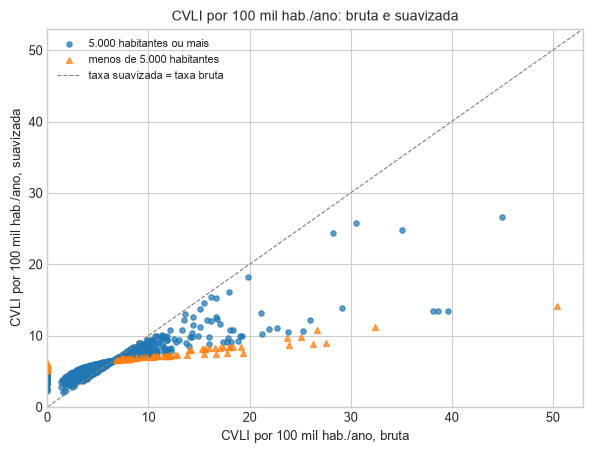

In [6]:
fig = plot_taxas_suavizadas(modelagem["taxa_cvli"], suavizada["taxa_cvli"],
                            modelagem["flag_pop_pequena"],
                            "CVLI por 100 mil hab./ano")
salvar(fig, "figura_taxas_suavizadas")

## 5. Perfis com as taxas suavizadas

A matriz é refeita com as taxas suavizadas no lugar das brutas (as outras 13
features não mudam), pela mesma função `montar_matriz`, e agrupada com o
modelo do `config.py`. Os grupos são renumerados pelo critério
socioeconômico do notebook 05. O ARI é calculado nos 644 municípios e,
separadamente, nos 149 pequenos e nos 495 demais (nesse caso, as duas
partições são restritas aos mesmos municípios antes da comparação).

In [7]:
referencia = perfis["perfil"].to_numpy()
perfil_suav, Z_suav, W_suav = refazer_particao(
    suavizada, features, bloco_de, ALGORITMO_ESCOLHIDO, K_ESCOLHIDO)

ari = {
    "ari_644": adjusted_rand_score(referencia, perfil_suav),
    "ari_149_pequenos": adjusted_rand_score(referencia[pequeno], perfil_suav[pequeno]),
    "ari_495_demais": adjusted_rand_score(referencia[~pequeno], perfil_suav[~pequeno]),
}
for nome, valor in ari.items():
    print(f"{nome}: {valor:.3f} ({faixa_ari(valor)})")
mudaram = perfil_suav != referencia
print(f"municípios que mudaram de perfil: {mudaram.sum()} "
      f"({pequeno[mudaram].sum()} pequenos)")

ari_644: 0.551 (os perfis dependem da mudança testada)
ari_149_pequenos: 0.713 (os perfis mudam em parte)
ari_495_demais: 0.504 (os perfis dependem da mudança testada)
municípios que mudaram de perfil: 113 (12 pequenos)


In [8]:
# crosstab conta quantos municípios há em cada combinação de perfis.
pd.crosstab(pd.Series(referencia, name="perfil original"),
            pd.Series(perfil_suav, name="perfil suavizado"),
            margins=True, margins_name="total")

perfil suavizado,1,2,3,4,total
perfil original,,,,,
1,65,1,0,0,66
2,2,213,0,2,217
3,4,59,131,2,196
4,0,31,12,122,165
total,71,304,143,126,644


## 6. Estabilidade e silhueta

O teste "sem os municípios pequenos" do notebook 05 é refeito sobre a base
suavizada: os 149 pequenos saem, a matriz é refeita com os 495 restantes e
o resultado é comparado com a partição suavizada restrita aos mesmos
municípios. A silhueta da partição suavizada é calculada na sua própria
matriz. Os valores originais são recalculados e conferidos com a
`tabela_comparacao_algoritmos.csv` do notebook 05.

In [9]:
_, W, _ = montar_matriz(modelagem, features, bloco_de)
original = comparacao[(comparacao["algoritmo"] == ALGORITMO_ESCOLHIDO)
                      & (comparacao["k"] == K_ESCOLHIDO)].iloc[0]

sem_peq_original = ari_sem_pequenos(modelagem, features, bloco_de,
                                    ALGORITMO_ESCOLHIDO, K_ESCOLHIDO, referencia)
sem_peq_suav = ari_sem_pequenos(suavizada, features, bloco_de,
                                ALGORITMO_ESCOLHIDO, K_ESCOLHIDO, perfil_suav)
silhueta_original = silhouette_score(W, referencia)
silhueta_suav = silhouette_score(W_suav, perfil_suav)
assert np.isclose(sem_peq_original, original["ari_sem_pequenos"])
assert np.isclose(silhueta_original, original["silhueta"])

print(f"ARI sem os pequenos: original {sem_peq_original:.3f} | "
      f"suavizado {sem_peq_suav:.3f}")
print(f"silhueta: original {silhueta_original:.3f} | suavizado {silhueta_suav:.3f}")

ARI sem os pequenos: original 0.480 | suavizado 0.822
silhueta: original 0.101 | suavizado 0.115


## 7. Saídas

A `tabela_taxas_suavizadas.csv` traz uma linha por medida. Nas três linhas
de ARI contra o `perfis.csv`, o valor original é 1 por definição, pois a
partição original comparada consigo mesma é idêntica.

In [10]:
tabela = pd.DataFrame([
    {"medida": "ari_644", "original": 1.0, "suavizado": ari["ari_644"]},
    {"medida": "ari_149_pequenos", "original": 1.0,
     "suavizado": ari["ari_149_pequenos"]},
    {"medida": "ari_495_demais", "original": 1.0,
     "suavizado": ari["ari_495_demais"]},
    {"medida": "ari_sem_pequenos", "original": sem_peq_original,
     "suavizado": sem_peq_suav},
    {"medida": "silhueta", "original": silhueta_original,
     "suavizado": silhueta_suav},
    {"medida": "municipios_que_mudaram", "original": 0,
     "suavizado": int(mudaram.sum())},
])
tabela.to_csv(DATA_PROCESSED / "tabela_taxas_suavizadas.csv", index=False)

pd.DataFrame({
    "codigo_ibge": modelagem["codigo_ibge"],
    "municipio": modelagem["municipio"],
    "perfil_original": referencia,
    "perfil_suavizado": perfil_suav,
}).to_csv(DATA_PROCESSED / "perfis_suavizados.csv", index=False)
tabela.round(3)

,medida,original,suavizado
0,ari_644,1.000,0.551
1,ari_149_pequenos,1.000,0.713
2,ari_495_demais,1.000,0.504
3,ari_sem_pequenos,0.480,0.822
4,silhueta,0.101,0.115
5,municipios_que_mudaram,0.000,113.000


Os municípios que mudaram de perfil, agrupados pela mudança, com a população
mediana e quantos deles são pequenos:

In [11]:
trocas = modelagem.loc[mudaram, ["municipio", "populacao", "flag_pop_pequena"]].assign(
    de=referencia[mudaram], para=perfil_suav[mudaram])
trocas.groupby(["de", "para"]).agg(
    municipios=("municipio", "size"),
    pequenos=("flag_pop_pequena", "sum"),
    populacao_mediana=("populacao", "median"),
)

municipios  pequenos  populacao_mediana
de para                                         
1  2              1         1             4896.0
2  1              2         2             3413.0
   4              2         2             1528.5
3  1              4         0            17572.0
   2             59         4            12529.0
   4              2         0            33748.5
4  2             31         3            17156.0
   3             12         0           100497.0

Para os perfis 3 e 4, que perdem municípios, a célula abaixo compara as
taxas criminais medianas, brutas e suavizadas, dos municípios que saíram com
as dos que ficaram.

In [12]:
linhas = []
for p in [3, 4]:
    for situacao, filtro in [("ficaram", (referencia == p) & ~mudaram),
                             ("saíram", (referencia == p) & mudaram)]:
        linhas.append({"perfil_original": p, "situacao": situacao,
                       "municipios": int(filtro.sum()),
                       "roubo_outros_bruta": modelagem.loc[filtro, "taxa_roubo_outros"].median(),
                       "roubo_outros_suavizada": suavizada.loc[filtro, "taxa_roubo_outros"].median(),
                       "cvli_bruta": modelagem.loc[filtro, "taxa_cvli"].median(),
                       "cvli_suavizada": suavizada.loc[filtro, "taxa_cvli"].median(),
                       "populacao_mediana": modelagem.loc[filtro, "populacao"].median()})
pd.DataFrame(linhas).round(2)

,perfil_original,situacao,municipios,roubo_outros_bruta,roubo_outros_suavizada,cvli_bruta,cvli_suavizada,populacao_mediana
0,3,ficaram,131,58.39,59.89,8.14,7.46,32888.0
1,3,saíram,65,26.96,29.62,5.56,6.05,13058.0
2,4,ficaram,122,61.96,62.75,4.86,5.30,69056.0
3,4,saíram,43,33.33,34.31,7.02,6.79,24423.0


## 8. Leitura

**Os perfis dependem da suavização.** Com as taxas suavizadas, o ARI em
relação à partição de referência é de 0,551 nos 644 municípios, abaixo de
0,65, e 113 municípios mudam de perfil. A mudança não se concentra nos
municípios pequenos: apenas 12 dos 113 têm menos de 5.000 habitantes, o ARI
nos 149 pequenos é de 0,713 (os perfis mudam em parte) e, nos 495 demais, de
0,504 (os perfis dependem da mudança testada).

**Quais perfis mudam.** Os perfis 1 e 2 praticamente se mantêm (65 de 66 e
213 de 217 municípios). O perfil 3 perde 65 municípios, 59 deles para o
perfil 2, e o perfil 4 perde 43, sendo 31 para o perfil 2 e 12 para o
perfil 3; o perfil 2 passa de 217 para 304 municípios. Os municípios que
saem dos perfis 3 e 4 têm roubo de outros mediano (bruto) de 26,96 e 33,33
por 100 mil hab./ano, contra 58,39 e 61,96 nos que ficam, e população
mediana de 13.058 e 24.423 habitantes, contra 32.888 e 69.056.

**Estabilidade e separação.** Refeito sobre a base suavizada, o teste sem os
municípios pequenos passa de ARI 0,480 para 0,822, e a silhueta passa de
0,101 para 0,115. A partição obtida com as taxas suavizadas é, portanto,
mais estável à retirada dos municípios pequenos e um pouco mais separada,
mas é diferente da partição de referência.

A escolha entre manter os perfis com taxas brutas ou adotar as suavizadas
cabe ao grupo; este notebook não altera o `perfis.csv`.